# Modeling and Simulation: Problem Sheet 5, exercise 3(d)

Problem sheet 5, exercise 3(d).

Vertical shot of a projectile with quadratic air drag, solved until it
reaches its highest point.


    velocity : dv/dt = -g - (k/m) v^2     (forward Euler)

    position : dz/dt = v                  (forward finite difference)

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ---------------- parameters (SI units) ----------------
v0 = 250.0      # initial velocity in m/s
g = 9.81        # gravitational acceleration in m/s^2
rho = 1.2       # air density in kg/m^3
A = 0.09        # cross-sectional area in m^2
cw = 0.4        # drag coefficient (no unit)
m = 3.0         # mass in kg

k = 0.5 * cw * rho * A      # drag constant in kg/m, F_f = k v^2

In [4]:
# ---------------- numerical parameters ----------------
h = 0.001                   # time step in s
t_end = 10.0                # long enough; we stop at the highest point
N = int(t_end / h) + 1      # maximum number of time points

t = np.zeros(N)
v = np.zeros(N)
z = np.zeros(N)

# initial conditions: v(0) = v0, z(0) = 0
t[0] = 0.0
v[0] = v0
z[0] = 0.0

In [5]:
# ---------------- time stepping ----------------
i = 0
while v[i] > 0 and i < N - 1:
    # 3c(i): forward Euler for the velocity
    v[i + 1] = v[i] + h * (-g - (k / m) * v[i] ** 2)

    # 3c(ii): forward finite difference (z_{i+1} - z_i)/h = v_i
    z[i + 1] = z[i] + h * v[i]

    t[i + 1] = t[i] + h
    i = i + 1

# keep only the computed part (up to the first step where v <= 0)
t = t[: i + 1]
v = v[: i + 1]
z = z[: i + 1]

# the last step slightly overshoots below v = 0; interpolate the exact
# crossing to get the time and height of the highest point
t_top = t[-2] + h * v[-2] / (v[-2] - v[-1])
z_top = z[-2] + v[-2] * (t_top - t[-2]) / 2   # area of the last small triangle

# values after 3 seconds
j = int(round(3.0 / h))
print(f"k = {k:.4f} kg/m, terminal velocity sqrt(mg/k) = {np.sqrt(m * g / k):.2f} m/s")
print(f"maximum velocity v = {v.max():.2f} m/s at t = {t[np.argmax(v)]:.2f} s")
print(f"minimum velocity v = 0 m/s at the highest point")
print(f"after t = {t[j]:.2f} s: v = {v[j]:.2f} m/s, z = {z[j]:.2f} m")
print(f"highest point: t = {t_top:.3f} s, v = 0 m/s, z = {z_top:.2f} m")

k = 0.0216 kg/m, terminal velocity sqrt(mg/k) = 36.91 m/s
maximum velocity v = 250.00 m/s at t = 0.00 s
minimum velocity v = 0 m/s at the highest point
after t = 3.00 s: v = 26.71 m/s, z = 237.85 m
highest point: t = 5.357 s, v = 0 m/s, z = 267.11 m


In [6]:
# ---------------- check against the analytical solution ----------------
vt = np.sqrt(m * g / k)                       # terminal velocity
t_top_exact = vt / g * np.arctan(v0 / vt)
z_top_exact = m / (2 * k) * np.log(1 + k * v0 ** 2 / (m * g))
v3_exact = vt * np.tan(np.arctan(v0 / vt) - g * 3.0 / vt)
print(f"analytical: t_top = {t_top_exact:.3f} s, z_top = {z_top_exact:.2f} m, "
      f"v(3 s) = {v3_exact:.2f} m/s")

analytical: t_top = 5.359 s, z_top = 267.18 m, v(3 s) = 26.74 m/s


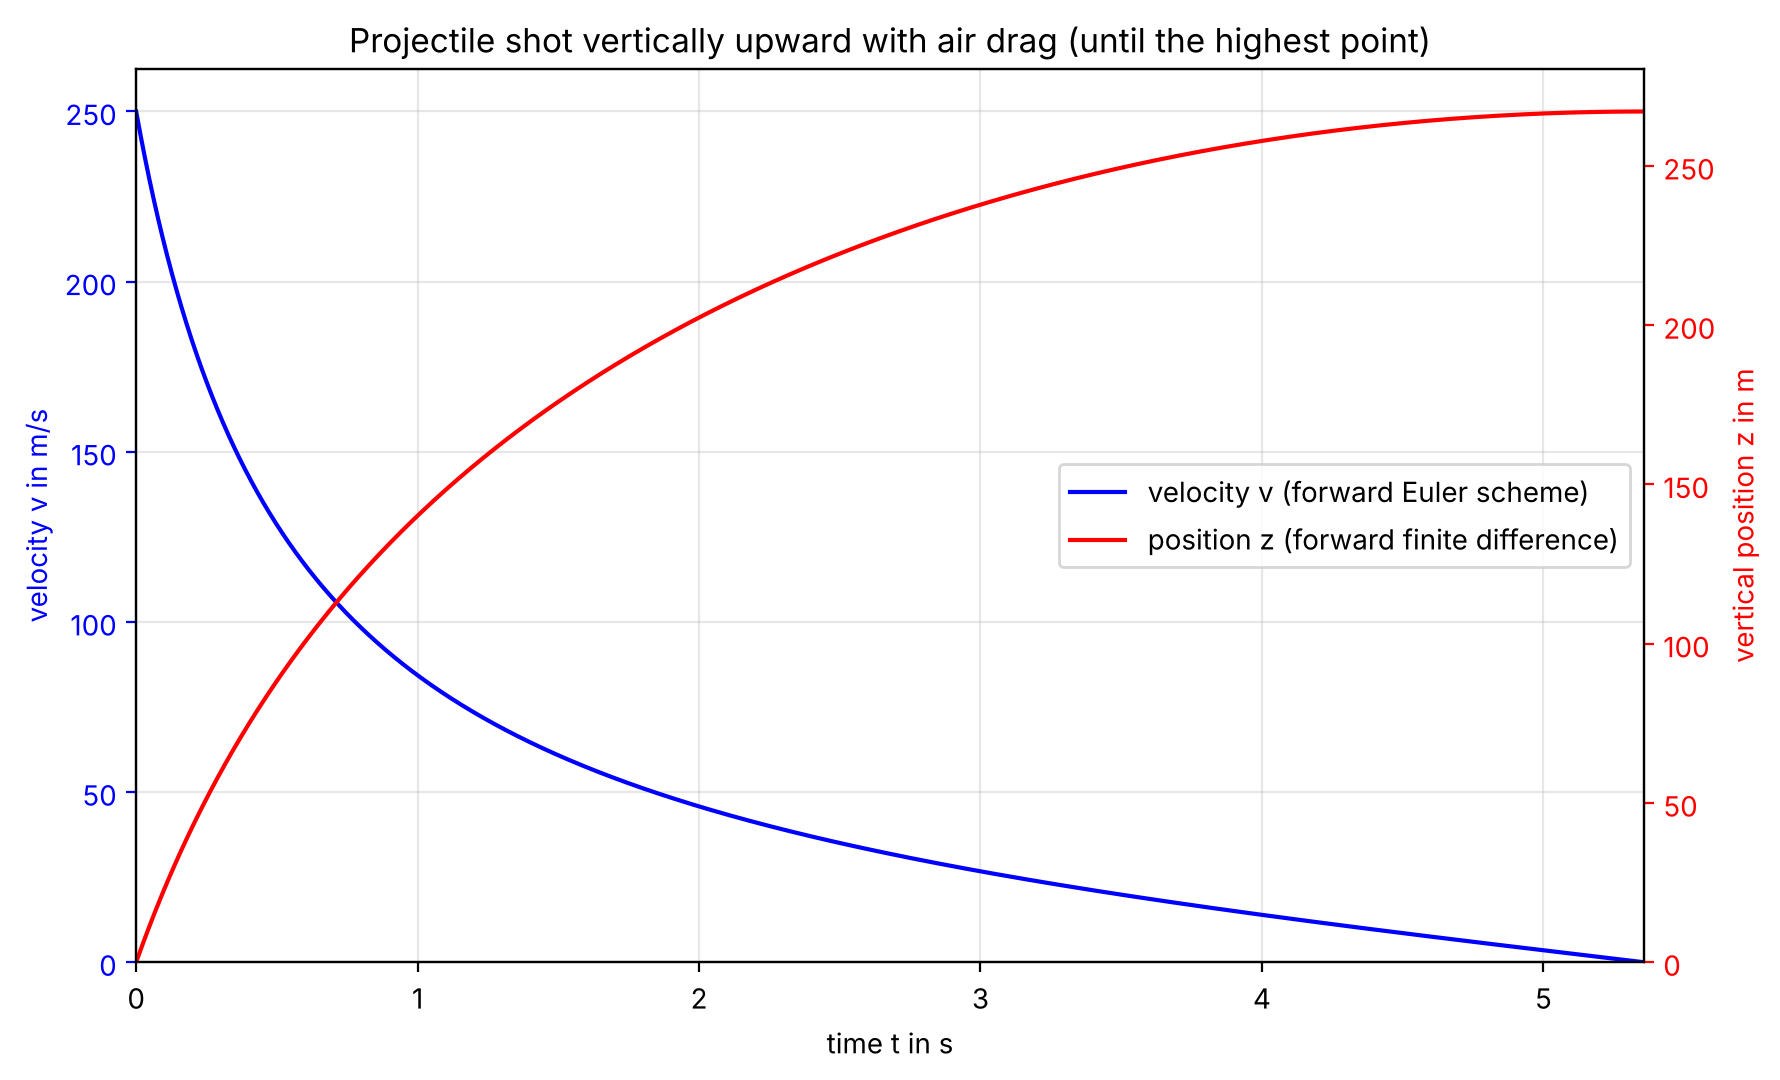

In [7]:
# ---------------- plot: two curves, two y-axes (as in Figure 1) ----------------
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax1.plot(t, v, color="blue", label="velocity v (forward Euler scheme)")
ax1.set_xlabel("time t in s")
ax1.set_ylabel("velocity v in m/s", color="blue")
ax1.tick_params(axis="y", colors="blue")

ax2 = ax1.twinx()
ax2.plot(t, z, color="red", label="position z (forward finite difference)")
ax2.set_ylabel("vertical position z in m", color="red")
ax2.tick_params(axis="y", colors="red")

ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)
ax1.set_xlim(0, t[-1])
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="center right")
ax1.set_title("Projectile shot vertically upward with air drag (until the highest point)")
ax1.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("ps_5_ex_3d_plot.png", dpi=200)
plt.show()

In [8]:
# ---------------- comments on the results ----------------
# * The velocity drops very fast at the start: at 250 m/s the drag force
#   k v^2 = 1350 N is about 46 times the weight m g = 29.4 N.
# * Once v is well below the terminal velocity (about 37 m/s), gravity
#   dominates and v falls almost linearly with slope -g.
# * The position rises steeply first and then flattens; the top is reached
#   when v = 0, after about 5.36 s at a height of about 267 m.
# * Without air the projectile would rise for v0/g = 25.5 s to v0^2/(2g)
#   = 3186 m, so drag reduces the height by more than a factor of 10.
# * The Euler results agree with the analytical solution to within about
#   0.1 %, which confirms the simulation (smaller h -> smaller error, O(h)).